# Milwaukee Property Sales Analysis — 2025

## Executive Summary

This project analyzes 2025 Milwaukee property sales data using Python, Pandas, Matplotlib, and Seaborn to identify trends in residential property prices, neighborhood differences, and property characteristics.

### Dataset Overview

- **Original records:** 5,685
- **Records after cleaning:** 5,580
- **Residential transactions:** 4,530
- **Empty records removed:** 105

### Key Findings

**1. Residential Property Prices**

The median residential sale price was $235,000, compared with an average of $245,267.

**2. Neighborhood Pricing Differences**

Neighborhood 3060 had the highest median residential sale price among neighborhoods with at least 10 transactions, at approximately $800,000.

Neighborhood 4560 ranked highest for median price per square foot, at approximately $315.

**3. Monthly Sales Trends**

Residential transaction volume peaked in May with 485 sales, while median prices reached their highest monthly level in June at $246,000.

**4. Property Characteristics**

Finished square footage had the strongest individual linear correlation with sale price (r = 0.355) among the characteristics tested.

Square footage and full bathroom count were also strongly associated (r = 0.65).

### Business Recommendations

- Use neighborhood-level median prices alongside transaction counts when comparing local markets.
- Consider price per square foot in addition to total sale price when evaluating residential properties.
- Account for changes in monthly transaction activity when planning sales and marketing efforts.
- Incorporate multiple property characteristics and neighborhood information into future pricing analyses.

### Conclusion

This project demonstrates the use of Python for data cleaning, exploratory analysis, statistical comparisons, and visualization. The findings provide a foundation for further real estate market research and more advanced predictive modeling.

In [4]:
import pandas as pd

# Load the property sales dataset
df = pd.read_csv("armslengthsales_2025_valid_20260417.csv")

# Display the first 5 rows
df.head()

,PropertyID,PropType,taxkey,Address,CondoProject,District,nbhd,Style,Extwall,Stories,...,Rooms,FinishedSqft,Units,SoldAsVacantLand,Bdrms,Fbath,Hbath,Lotsize,Sale_date,Sale_price
0,98467.0,Commercial,30171000.0,9400-9408 N 107TH ST,NaN,9.0,6202.0,Office Building - 1 Story,Concrete Block,1.0,...,NaN,12960.0,6.0,N,NaN,0.0,0.0,178160.0,10/15/2025,650000.0
1,98533.0,Residential,50014000.0,8529 W GLENBROOK RD,NaN,9.0,40.0,Ranch,Aluminum/Vinyl,1.0,...,5.0,1007.0,1.0,N,3.0,1.0,1.0,12000.0,11/26/2025,245000.0
2,98561.0,Residential,50042000.0,9322 N JOYCE AV,NaN,9.0,40.0,Ranch,Aluminum/Vinyl,1.0,...,10.0,1006.0,1.0,N,6.0,1.0,0.0,8303.0,7/18/2025,260000.0
3,98564.0,Residential,50045000.0,9340 N JOYCE AV,NaN,9.0,40.0,Split Level,Aluminum/Vinyl,1.5,...,12.0,1891.0,1.0,N,6.0,2.0,1.0,10367.0,6/25/2025,325000.0
4,98598.0,Residential,50079000.0,9355 N BURBANK AV,NaN,9.0,40.0,Ranch,Aluminum/Vinyl,1.0,...,5.0,1209.0,1.0,N,3.0,1.0,1.0,7200.0,10/22/2025,279900.0


In [5]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

('Dataset shape:', (5685, 21))

Columns:
['PropertyID', 'PropType', 'taxkey', 'Address', 'CondoProject', 'District', 'nbhd', 'Style', 'Extwall', 'Stories', 'Year_Built', 'Rooms', 'FinishedSqft', 'Units', 'SoldAsVacantLand', 'Bdrms', 'Fbath', 'Hbath', 'Lotsize', 'Sale_date', 'Sale_price']

Data types:
PropertyID          float64
PropType             object
taxkey              float64
Address              object
CondoProject         object
District            float64
nbhd                float64
Style                object
Extwall              object
Stories             float64
Year_Built          float64
Rooms               float64
FinishedSqft        float64
Units               float64
SoldAsVacantLand     object
Bdrms               float64
Fbath               float64
Hbath               float64
Lotsize             float64
Sale_date            object
Sale_price          float64
dtype: object

Missing values:
PropertyID           105
PropType             105
taxkey               105
Addr

In [6]:
# Check the dataset structure
df.info()

# Count missing values in each column
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5685 entries, 0 to 5684
Data columns (total 21 columns):
PropertyID          5580 non-null float64
PropType            5580 non-null object
taxkey              5580 non-null float64
Address             5577 non-null object
CondoProject        685 non-null object
District            5580 non-null float64
nbhd                5580 non-null float64
Style               5563 non-null object
Extwall             4863 non-null object
Stories             5551 non-null float64
Year_Built          5572 non-null float64
Rooms               5243 non-null float64
FinishedSqft        5558 non-null float64
Units               5580 non-null float64
SoldAsVacantLand    5580 non-null object
Bdrms               5243 non-null float64
Fbath               5580 non-null float64
Hbath               5580 non-null float64
Lotsize             5580 non-null float64
Sale_date           5580 non-null object
Sale_price          5580 non-null float64
dtypes: float64(14)

PropertyID           105
PropType             105
taxkey               105
Address              108
CondoProject        5000
District             105
nbhd                 105
Style                122
Extwall              822
Stories              134
Year_Built           113
Rooms                442
FinishedSqft         127
Units                105
SoldAsVacantLand     105
Bdrms                442
Fbath                105
Hbath                105
Lotsize              105
Sale_date            105
Sale_price           105
dtype: int64

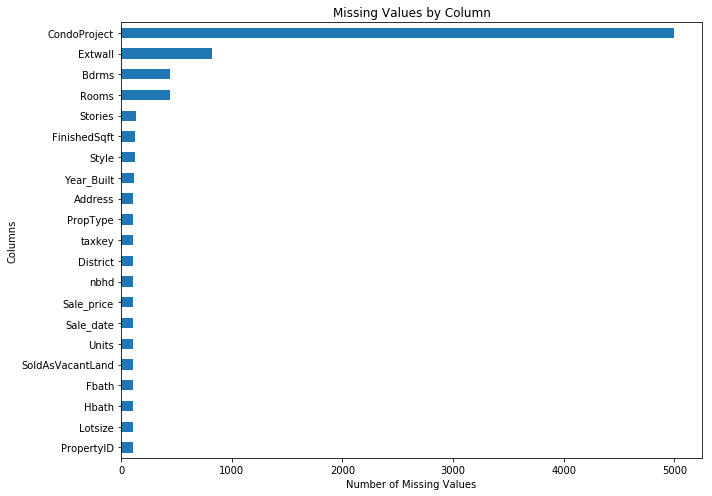

In [7]:
import matplotlib.pyplot as plt

# Calculate missing values
missing = df.isnull().sum()

# Keep columns with missing data
missing = missing[missing > 0].sort_values()

# Create chart
plt.figure(figsize=(10, 7))

missing.plot(kind="barh")

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")

plt.tight_layout()
plt.show()

In [9]:
# Count completely empty rows
empty_rows = df.isna().all(axis=1).sum()

print("Total rows:", len(df))
print("Completely empty rows:", empty_rows)
print("Rows missing sale price:", df["Sale_price"].isna().sum())

('Total rows:', 5685)
('Completely empty rows:', 105)
('Rows missing sale price:', 105)


In [10]:
# View records missing a sale price
missing_sales = df[df["Sale_price"].isna()]

display(missing_sales.head(10))

,PropertyID,PropType,taxkey,Address,CondoProject,District,nbhd,Style,Extwall,Stories,...,Rooms,FinishedSqft,Units,SoldAsVacantLand,Bdrms,Fbath,Hbath,Lotsize,Sale_date,Sale_price
5580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5583,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5584,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5585,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5586,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5587,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5588,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Cleaning

### Investigating Missing Values

The dataset contains 5,685 records and 21 columns.

Initial exploratory analysis identified 105 records
with missing sale prices.

Before removing these records, I investigated
whether they were completely empty or contained
other useful property information.

In [13]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove completely empty rows
df_clean = df_clean.dropna(how="all")

# Reset row numbering
df_clean = df_clean.reset_index(drop=True)

# Compare original and cleaned datasets
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

('Original rows:', 5685)
('Cleaned rows:', 5580)
('Rows removed:', 105)


In [14]:
# Check exact duplicate rows
print("Exact duplicate rows:",
      df_clean.duplicated().sum())

# Check repeated PropertyIDs
print("Repeated PropertyIDs:",
      df_clean["PropertyID"].duplicated().sum())

# Display records with repeated PropertyIDs
duplicates = df_clean[
    df_clean.duplicated(subset=["PropertyID"], keep=False)
]

display(
    duplicates[
        ["PropertyID", "Address", "Sale_date", "Sale_price"]
    ].sort_values("PropertyID").head(20)
)

('Exact duplicate rows:', 0)
('Repeated PropertyIDs:', 83)


,PropertyID,Address,Sale_date,Sale_price
91,100953.0,7601 W HEATHER AV,2/5/2025,103000.0
92,100953.0,7601 W HEATHER AV,4/10/2025,143000.0
123,102115.0,10208 W TERRA AV,8/20/2025,179900.0
124,102115.0,10208 W TERRA AV,12/11/2025,365000.0
241,105309.0,10000 W GREEN TREE RD,1/14/2025,199900.0
242,105309.0,10000 W GREEN TREE RD,11/5/2025,350000.0
256,105660.0,8903 W CHEYENNE ST,6/22/2025,166000.0
257,105660.0,8903 W CHEYENNE ST,11/12/2025,290000.0
370,109253.0,6564 N 91ST ST,12/15/2025,185000.0
369,109253.0,6564 N 91ST ST,9/5/2025,158000.0


Data Cleaning — Removing Empty Records

The original dataset contained 5,685 rows. During the data quality assessment, I identified 105 completely empty records.

These records were excluded because they contained no usable transaction or property information.

After removing these rows, the dataset contained 5,580 records available for further analysis.
The original dataset was preserved, and all cleaning operations were performed on a separate DataFrame.

In [15]:
# Find properties with repeated IDs
repeated_properties = df_clean[
    df_clean.duplicated(subset=["PropertyID"], keep=False)
]

# Display their transaction details
display(
    repeated_properties[
        ["PropertyID", "Address", "Sale_date", "Sale_price", "PropType"]
    ]
    .sort_values(["PropertyID", "Sale_date"])
    .head(30)
)

,PropertyID,Address,Sale_date,Sale_price,PropType
91,100953.0,7601 W HEATHER AV,2/5/2025,103000.0,Condominium
92,100953.0,7601 W HEATHER AV,4/10/2025,143000.0,Condominium
124,102115.0,10208 W TERRA AV,12/11/2025,365000.0,Residential
123,102115.0,10208 W TERRA AV,8/20/2025,179900.0,Residential
241,105309.0,10000 W GREEN TREE RD,1/14/2025,199900.0,Residential
242,105309.0,10000 W GREEN TREE RD,11/5/2025,350000.0,Residential
257,105660.0,8903 W CHEYENNE ST,11/12/2025,290000.0,Residential
256,105660.0,8903 W CHEYENNE ST,6/22/2025,166000.0,Residential
370,109253.0,6564 N 91ST ST,12/15/2025,185000.0,Residential
369,109253.0,6564 N 91ST ST,9/5/2025,158000.0,Residential


In [16]:
# Identify possible duplicate transactions
potential_duplicates = df_clean.duplicated(
    subset=["PropertyID", "Sale_date", "Sale_price"],
    keep=False
)

print(
    "Records in potential duplicate groups:",
    potential_duplicates.sum()
)

display(
    df_clean.loc[
        potential_duplicates,
        ["PropertyID", "Address", "Sale_date", "Sale_price"]
    ].sort_values(["PropertyID", "Sale_date"]).head(20)
)

('Records in potential duplicate groups:', 0)


,PropertyID,Address,Sale_date,Sale_price


## 3. Property Sales Analysis

### Business Question 1:
What is the typical property sale price in Milwaukee in 2025?

We will calculate the average, median, minimum,
and maximum sale prices to understand the market.

In [20]:
# Analyze property sale prices
sales = df_clean["Sale_price"]

print("Total Transactions:", len(sales))
print("Average Sale Price: ${:,.2f}".format(sales.mean()))
print("Median Sale Price: ${:,.2f}".format(sales.median()))
print("Minimum Sale Price: ${:,.2f}".format(sales.min()))
print("Maximum Sale Price: ${:,.2f}".format(sales.max()))

('Total Transactions:', 5580)
Average Sale Price: $326,517.96
Median Sale Price: $240,000.00
Minimum Sale Price: $1,500.00
Maximum Sale Price: $40,900,000.00


In [21]:
# Identify the 10 most expensive property sales
top_sales = df_clean.nlargest(10, "Sale_price")

display(
    top_sales[
        [
            "PropType",
            "Address",
            "Sale_date",
            "Sale_price",
            "FinishedSqft"
        ]
    ]
)

,PropType,Address,Sale_date,Sale_price,FinishedSqft
2668,Commercial,2350 N LAKE DR,9/26/2025,40900000.0,162000.0
5386,Lg Apartment,4568 S 20TH ST,11/19/2025,19800000.0,152130.0
3482,Lg Apartment,1009 W JUNEAU AV,6/30/2025,19200000.0,209034.0
3845,Lg Apartment,924 S 5TH ST,5/9/2025,16800000.0,83003.0
3568,Commercial,"320 E BUFFALO ST, Unit 100",3/27/2025,13000000.0,13527.0
3569,Commercial,"320 E BUFFALO ST, Unit 106",3/27/2025,13000000.0,918.0
3570,Commercial,"320 E BUFFALO ST, Unit 108",3/27/2025,13000000.0,267.0
3571,Commercial,"320 E BUFFALO ST, Unit 200",3/27/2025,13000000.0,18232.0
3572,Commercial,"320 E BUFFALO ST, Unit 300",3/27/2025,13000000.0,17820.0
3573,Commercial,"320 E BUFFALO ST, Unit 400",3/27/2025,13000000.0,14790.0


In [22]:
# Calculate sales statistics by property type
property_summary = (
    df_clean.groupby("PropType")["Sale_price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(property_summary)

,count,mean,median,min,max
PropType,,,,,
Exempt,1,750000.00,750000.0,750000.0,750000.0
Lg Apartment,188,905741.08,447500.0,50000.0,19800000.0
Commercial,173,1926476.83,415000.0,60000.0,40900000.0
Residential,4530,245267.05,235000.0,1500.0,1610000.0
Condominium,688,300291.67,220000.0,38500.0,2450000.0


Finding 1: Property Sale Price Distribution

Analysis of 5,580 property transactions in 2025 revealed an average sale price of $326,517.96 and a median sale price of $240,000.

The average was approximately 36% higher than the median, suggesting a positively skewed price distribution.

Sale prices ranged from $1,500 to $40.9 million, indicating substantial variation across transactions.

Next analytical step: Segment transactions by property type to determine how commercial and other high-value sales influence overall pricing statistics.

## 4. Residential Property Market Analysis

### Business Question
How do residential property sale prices vary across
Milwaukee neighborhoods?

Residential properties represent the majority of
transactions in the dataset. This analysis focuses
on residential sales to reduce distortions caused
by differences between property types.

In [23]:
# Create a residential property dataset
residential = df_clean[
    df_clean["PropType"] == "Residential"
].copy()

# Confirm number of transactions
print("Residential transactions:", len(residential))

# Calculate residential price statistics
print("Median price: ${:,.2f}".format(
    residential["Sale_price"].median()
))

print("Average price: ${:,.2f}".format(
    residential["Sale_price"].mean()
))

('Residential transactions:', 4530)
Median price: $235,000.00
Average price: $245,267.05


In [25]:
# Group residential properties by neighborhood
neighborhood_sales = (
    residential.groupby("nbhd")["Sale_price"]
    .agg(["count", "median", "mean"])
    .reset_index()
)

# Rename columns
neighborhood_sales.columns = [
    "nbhd",
    "total_sales",
    "median_price",
    "average_price"
]

# Keep neighborhoods with at least 10 sales
neighborhood_sales = neighborhood_sales[
    neighborhood_sales["total_sales"] >= 10
]

# Find top 10 neighborhoods
top_neighborhoods = (
    neighborhood_sales
    .sort_values("median_price", ascending=False)
    .head(10)
)

display(top_neighborhoods)

,nbhd,total_sales,median_price,average_price
90,3060.0,37,800000.0,811552.702703
125,4560.0,16,655000.0,652262.500000
92,3160.0,43,445000.0,454460.465116
81,2910.0,16,434350.0,421971.875000
93,3170.0,20,429500.0,438475.000000
128,4610.0,19,415000.0,391268.421053
127,4600.0,15,412000.0,405393.333333
124,4540.0,35,405000.0,420890.000000
95,3240.0,16,380250.0,369950.937500
121,4500.0,33,379000.0,390334.848485


### Top 10 Milwaukee Neighborhoods by Median Residential Sale Price

This analysis compares median residential sale prices
across neighborhoods with at least 10 recorded sales.



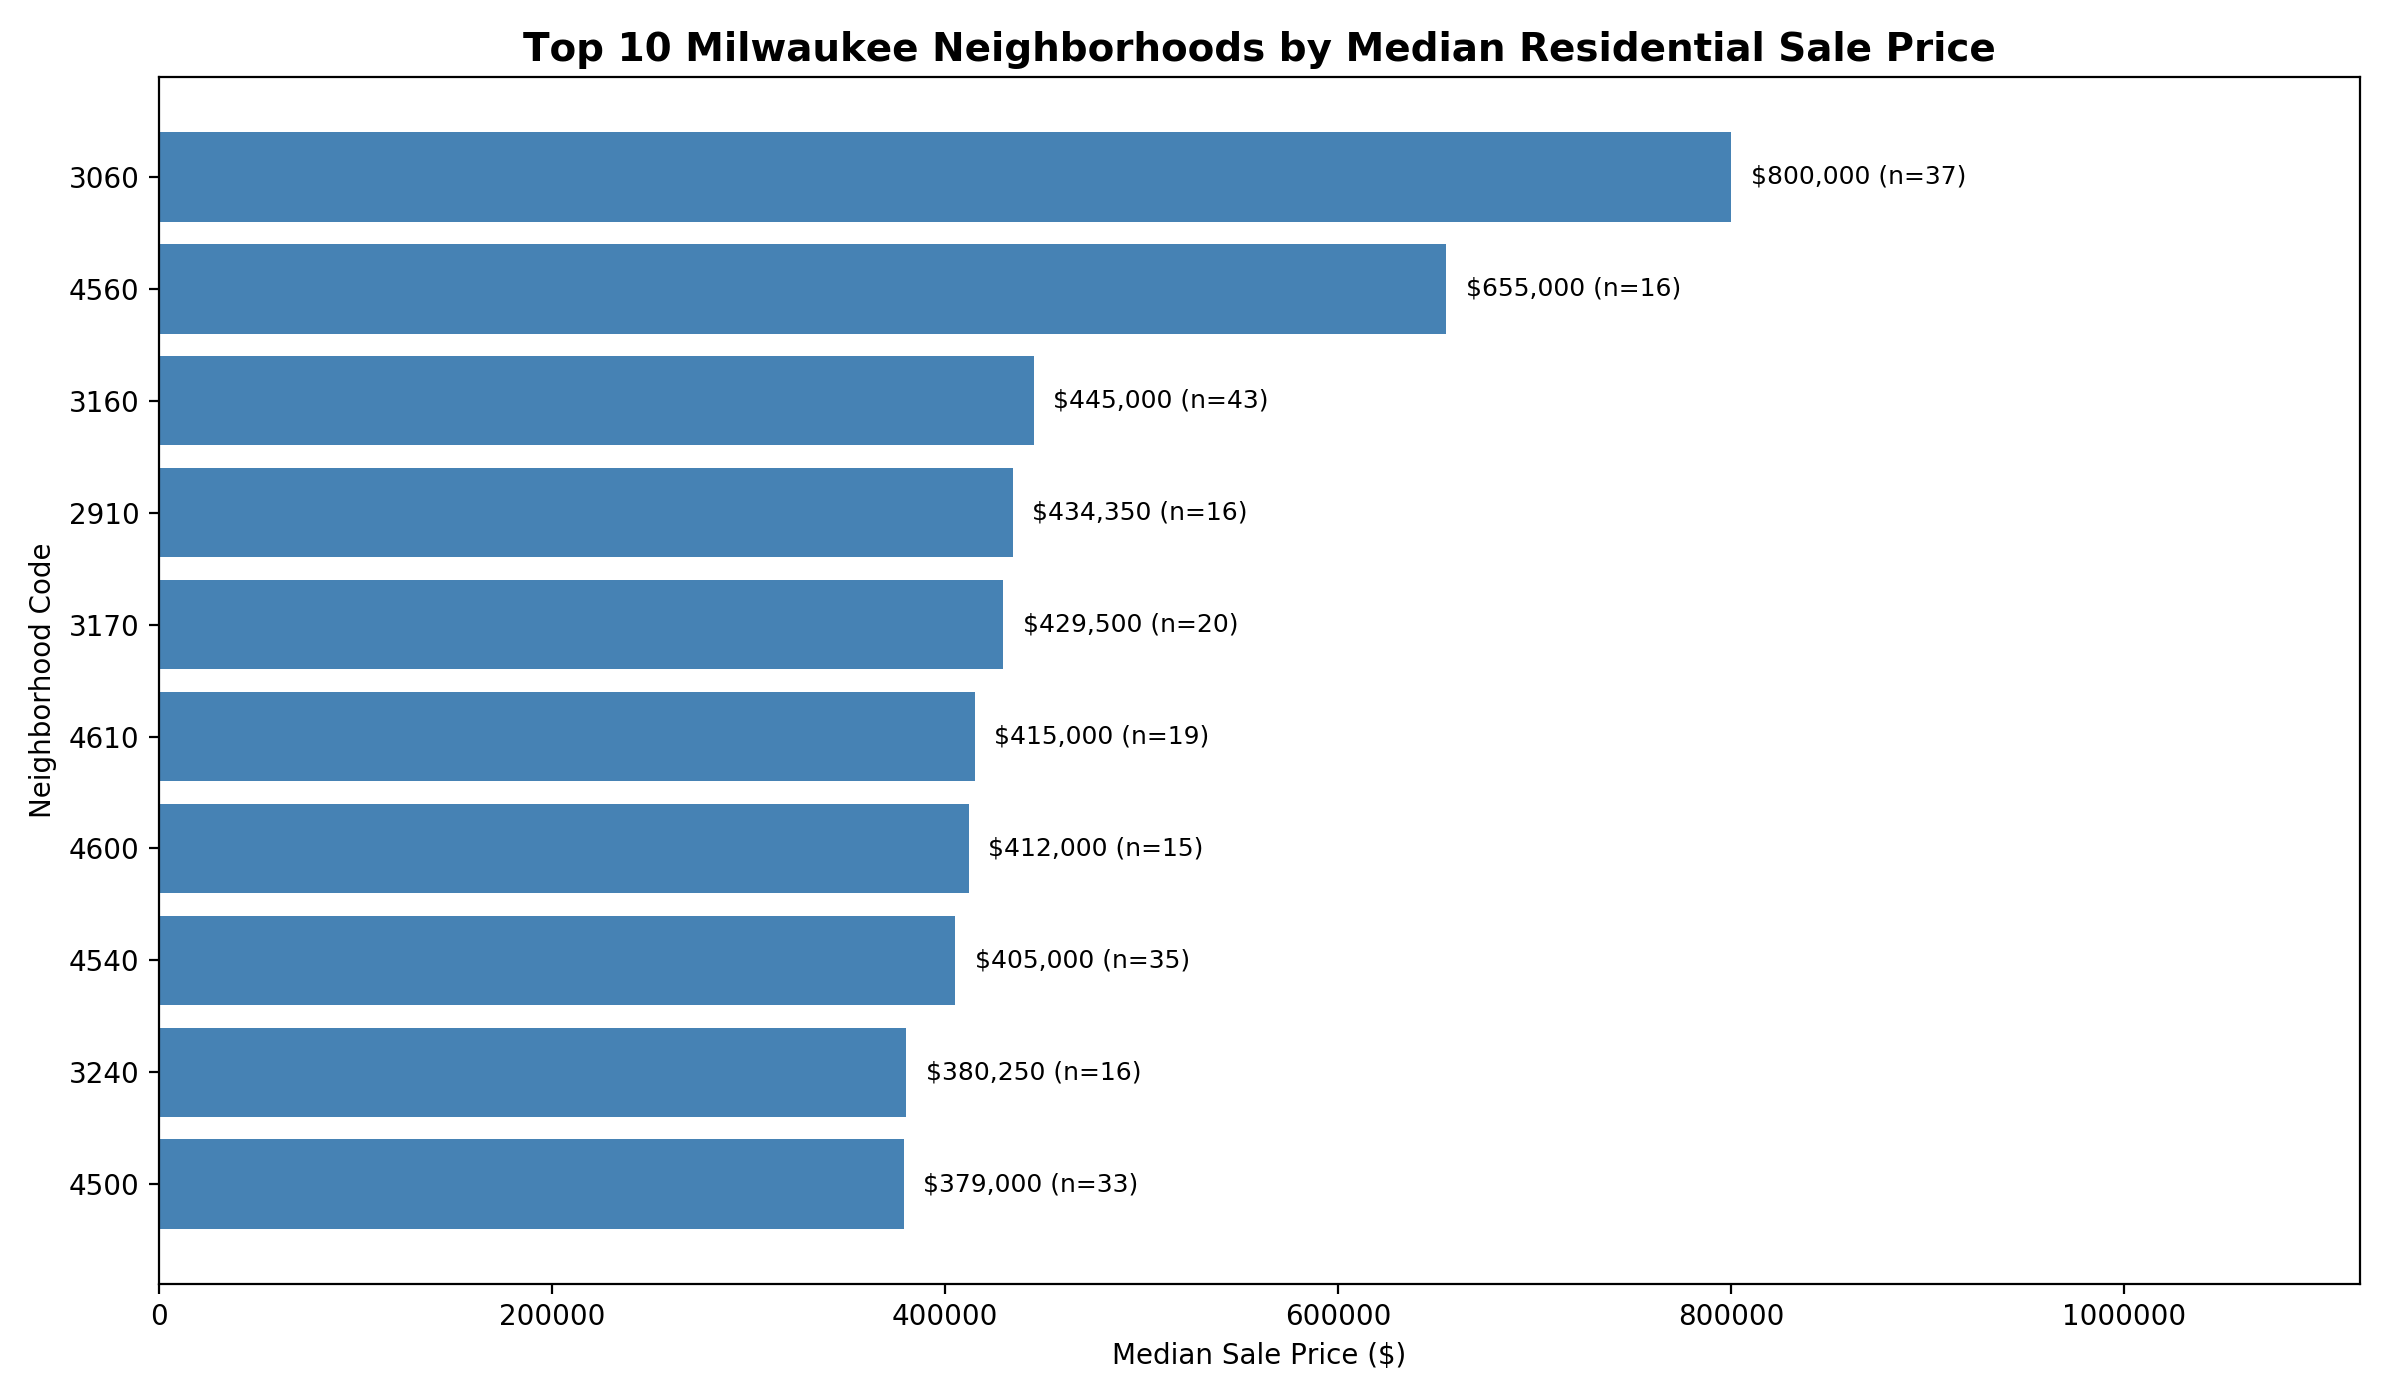

In [33]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Prepare data
chart_data = top_neighborhoods.sort_values("median_price").copy()

# Format neighborhood codes
chart_data["neighborhood"] = (
    chart_data["nbhd"].astype(int).astype(str)
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["neighborhood"],
    chart_data["median_price"],
    color="steelblue"
)

# Add price and transaction count labels
for bar, price, count in zip(
    bars,
    chart_data["median_price"],
    chart_data["total_sales"]
):
    ax.text(
        bar.get_width() + 10000,
        bar.get_y() + bar.get_height() / 2,
        "${:,.0f} (n={})".format(price, count),
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 10 Milwaukee Neighborhoods by Median Residential Sale Price",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Median Sale Price ($)")
ax.set_ylabel("Neighborhood Code")

ax.set_xlim(0, chart_data["median_price"].max() * 1.4)

plt.tight_layout()

fig.savefig("neighborhood_analysis_final.png", dpi=200)
plt.close(fig)

display(Image(filename="neighborhood_analysis_final.png"))

Finding 2: Neighborhood Price Differences
The neighborhood analysis identified substantial differences in median residential sale prices across Milwaukee in 2025.

Neighborhood code 3060 recorded the highest median sale price among neighborhoods with at least 10 transactions, at approximately $800,000.

Neighborhood codes 4560 and 3160 followed with median prices of approximately $655,000 and $445,000, respectively.

These results indicate geographic variation in residential property pricing. Further analysis of square footage, property age, and transaction volume is needed to better understand the differences.

In [32]:
# Display the top 10 neighborhoods with formatted prices
results = top_neighborhoods.copy()

results["median_price"] = results["median_price"].map(
    lambda x: "${:,.0f}".format(x)
)

results["average_price"] = results["average_price"].map(
    lambda x: "${:,.0f}".format(x)
)

display(results)

,nbhd,total_sales,median_price,average_price
90,3060.0,37,"$800,000","$811,553"
125,4560.0,16,"$655,000","$652,262"
92,3160.0,43,"$445,000","$454,460"
81,2910.0,16,"$434,350","$421,972"
93,3170.0,20,"$429,500","$438,475"
128,4610.0,19,"$415,000","$391,268"
127,4600.0,15,"$412,000","$405,393"
124,4540.0,35,"$405,000","$420,890"
95,3240.0,16,"$380,250","$369,951"
121,4500.0,33,"$379,000","$390,335"


### Neighborhood Pricing Analysis — Key Findings

This analysis examined residential property sales
across Milwaukee neighborhoods in 2025.

Neighborhoods with fewer than 10 transactions
were excluded to reduce the influence of small samples.

Median sale prices were used instead of averages
to limit the impact of unusually expensive sales.

The analysis identifies neighborhoods with relatively
high residential sale prices and provides a foundation
for further geographic market comparisons.

## 5. Price Per Square Foot Analysis

### Business Question
Which Milwaukee neighborhoods have the highest residential
sale prices relative to property size?

This analysis calculates price per finished square foot
to compare properties of different sizes.

In [34]:
# Create a separate dataset for price per square foot
residential_sqft = residential.copy()

# Keep properties with valid square footage and positive prices
residential_sqft = residential_sqft[
    (residential_sqft["FinishedSqft"] > 0) &
    (residential_sqft["Sale_price"] > 0)
].copy()

# Calculate price per square foot
residential_sqft["PricePerSqft"] = (
    residential_sqft["Sale_price"] /
    residential_sqft["FinishedSqft"]
)

# Review results
display(
    residential_sqft[
        ["Sale_price", "FinishedSqft", "PricePerSqft"]
    ].head(10)
)

,Sale_price,FinishedSqft,PricePerSqft
1,245000.0,1007.0,243.296922
2,260000.0,1006.0,258.449304
3,325000.0,1891.0,171.866737
4,279900.0,1209.0,231.513648
5,264000.0,1481.0,178.257934
6,384900.0,2244.0,171.524064
22,385000.0,1464.0,262.978142
24,400000.0,757.0,528.401585
25,410000.0,1608.0,254.975124
26,274000.0,1416.0,193.502825


In [35]:
# Summary statistics
print(
    residential_sqft["PricePerSqft"].describe()
)

# Examine the 10 highest values
display(
    residential_sqft.nlargest(10, "PricePerSqft")[
        ["Address", "Sale_price",
         "FinishedSqft", "PricePerSqft"]
    ]
)

count    4509.000000
mean      171.639914
std        77.792614
min        12.651822
25%       109.170306
50%       170.403587
75%       228.883495
max       528.401585
Name: PricePerSqft, dtype: float64


,Address,Sale_price,FinishedSqft,PricePerSqft
24,6908 W BEATRICE CT,400000.0,757.0,528.401585
4364,2511 S SUPERIOR ST,870000.0,1812.0,480.132450
4437,2730 S LENOX ST,565000.0,1185.0,476.793249
1833,1709 E NEWPORT AV,329000.0,709.0,464.033850
3670,7333 W BLUE MOUND RD,385000.0,864.0,445.601852
4946,3273 S DAYFIELD AV,400000.0,930.0,430.107527
4956,3412 S ALABAMA AV,335000.0,784.0,427.295918
4406,2879 S SUPERIOR ST,775000.0,1829.0,423.728814
4399,2778 S FULTON ST,314000.0,742.0,423.180593
4660,3427 S 80TH ST,325000.0,784.0,414.540816


In [36]:
# Group by neighborhood
sqft_neighborhood = (
    residential_sqft.groupby("nbhd")["PricePerSqft"]
    .agg(["count", "median", "mean"])
    .reset_index()
)

# Rename columns
sqft_neighborhood.columns = [
    "nbhd",
    "total_sales",
    "median_price_sqft",
    "average_price_sqft"
]

# Keep neighborhoods with at least 10 sales
sqft_neighborhood = sqft_neighborhood[
    sqft_neighborhood["total_sales"] >= 10
]

# Find top 10 neighborhoods
top_sqft = (
    sqft_neighborhood
    .sort_values("median_price_sqft", ascending=False)
    .head(10)
)

display(top_sqft.round(2))

,nbhd,total_sales,median_price_sqft,average_price_sqft
125,4560.0,15,315.10,330.63
139,4920.0,22,288.20,270.53
126,4580.0,65,279.28,274.72
136,4840.0,22,267.92,264.92
116,4380.0,32,266.78,259.54
133,4740.0,17,262.44,257.24
124,4540.0,35,259.84,268.58
110,4310.0,20,254.61,248.95
121,4500.0,33,253.76,256.85
72,2760.0,20,253.23,257.57


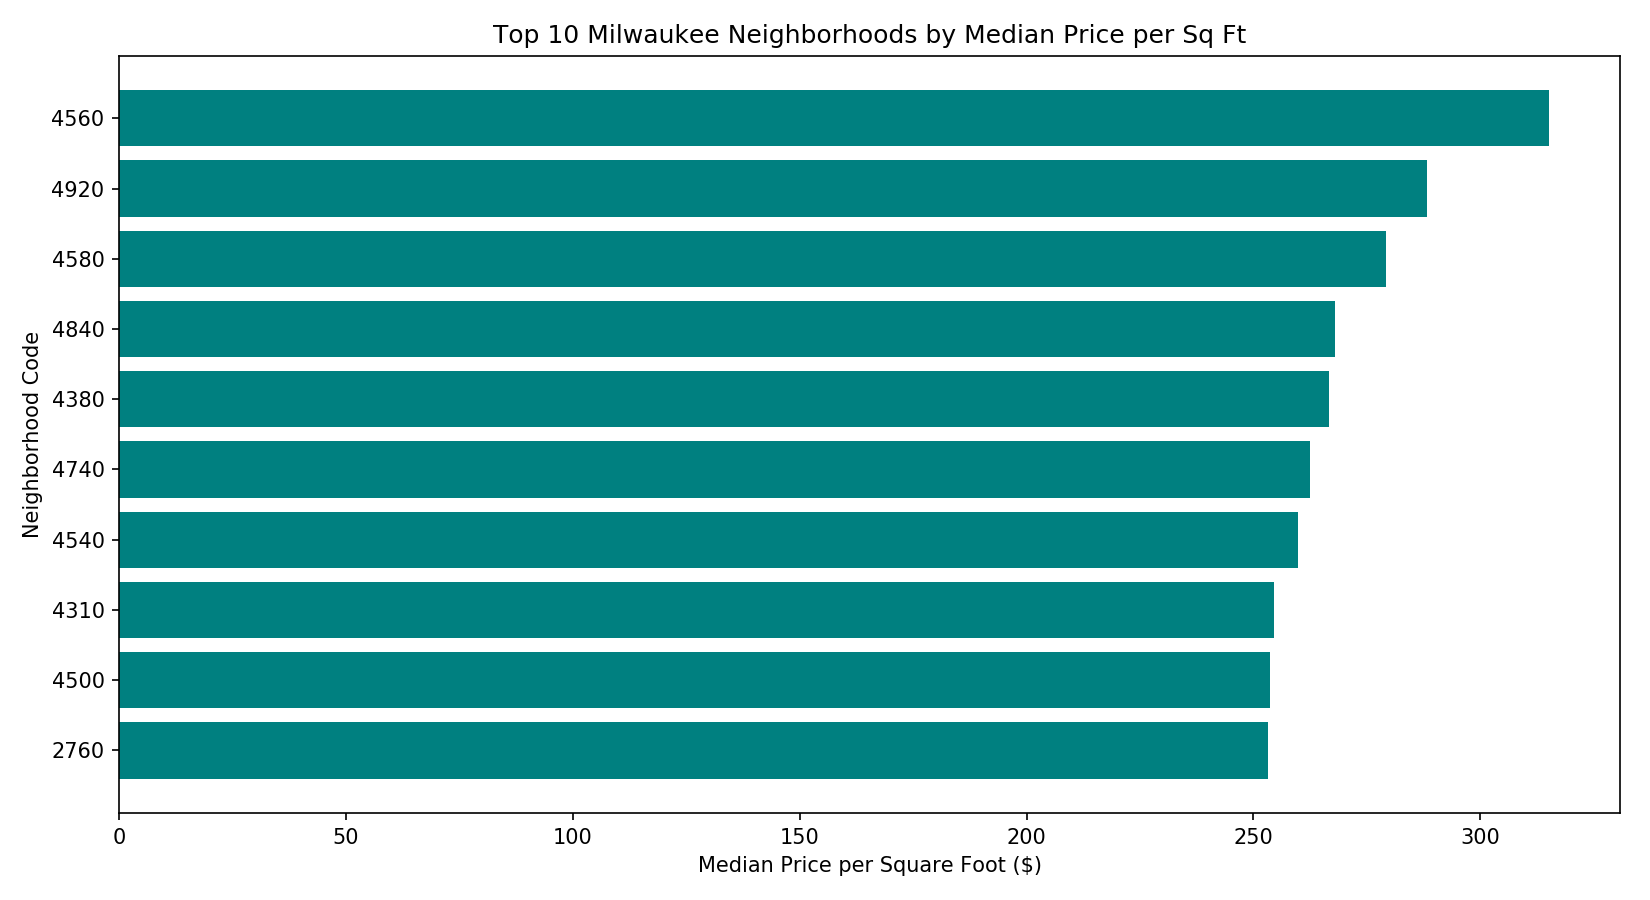

In [37]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

chart_data = top_sqft.sort_values("median_price_sqft").copy()

chart_data["neighborhood"] = (
    chart_data["nbhd"].astype(int).astype(str)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    chart_data["neighborhood"],
    chart_data["median_price_sqft"],
    color="teal"
)

ax.set_title(
    "Top 10 Milwaukee Neighborhoods by Median Price per Sq Ft"
)

ax.set_xlabel("Median Price per Square Foot ($)")
ax.set_ylabel("Neighborhood Code")

plt.tight_layout()

fig.savefig("price_per_sqft_neighborhood.png", dpi=150)
plt.close(fig)

display(Image(filename="price_per_sqft_neighborhood.png"))

### Finding 3: Neighborhood Price Per Square Foot

The analysis identified substantial differences in median
price per square foot across Milwaukee neighborhoods.

Neighborhood 4560 recorded the highest median price per
square foot, at approximately $315.

Interestingly, neighborhood 3060 ranked highest for total
median sale price but did not appear among the top 10
neighborhoods by price per square foot.

This suggests that total sale prices alone may not provide
a complete picture of neighborhood property values.

Further analysis of property size, age, and characteristics
could help explain these differences.

In [39]:
# Convert sale dates to datetime
residential["Sale_date"] = pd.to_datetime(
    residential["Sale_date"],
    errors="coerce"
)

# Check for dates that couldn't be converted
print(
    "Invalid sale dates:",
    residential["Sale_date"].isna().sum()
)

# Extract the month
residential["Sale_Month"] = (
    residential["Sale_date"].dt.month
)

('Invalid sale dates:', 0)


In [40]:
# Analyze monthly residential sales
monthly_sales = (
    residential.groupby("Sale_Month")["Sale_price"]
    .agg(["count", "median", "mean"])
    .reset_index()
)

monthly_sales.columns = [
    "Month",
    "Total_Sales",
    "Median_Price",
    "Average_Price"
]

display(monthly_sales.round(2))

,Month,Total_Sales,Median_Price,Average_Price
0,1,265,219000.0,230631.32
1,2,257,225000.0,235521.78
2,3,351,230000.0,235806.92
3,4,383,233000.0,245319.78
4,5,485,242000.0,246704.94
5,6,476,246000.0,254630.14
6,7,441,245000.0,256625.25
7,8,380,239900.0,252635.42
8,9,409,235000.0,244358.14
9,10,396,235000.0,242408.71


## 6. Monthly Residential Sales Trends

### Business Question
How did residential transaction volume and median sale
prices change throughout 2025?

This analysis examines monthly sales activity and pricing
patterns to identify potential seasonal trends.

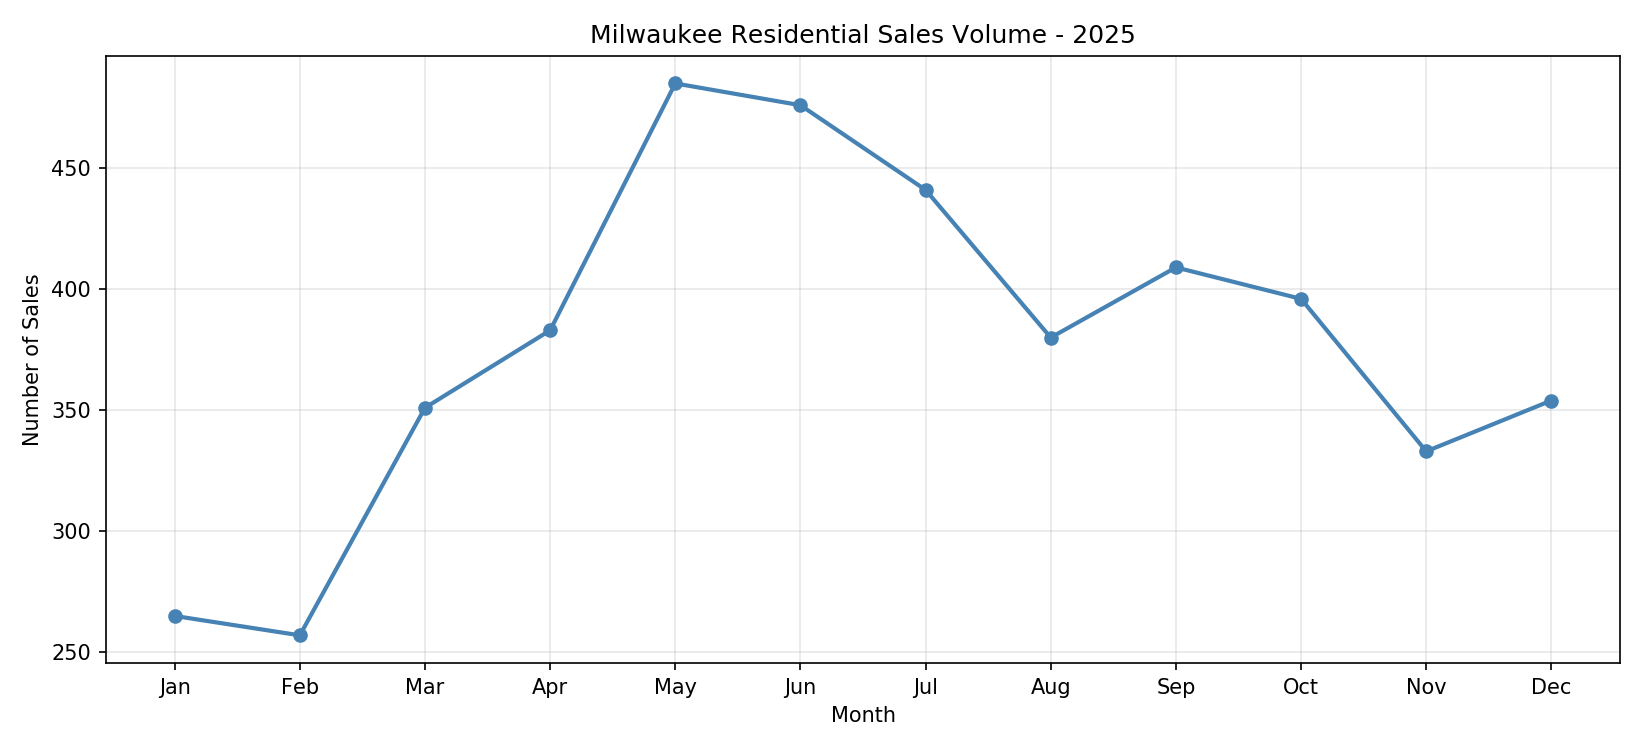

In [41]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Month labels
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create first chart: sales volume
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    months,
    monthly_sales["Total_Sales"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

ax.set_title("Milwaukee Residential Sales Volume - 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sales")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("monthly_sales_volume.png", dpi=150)
plt.close(fig)

display(Image(filename="monthly_sales_volume.png"))

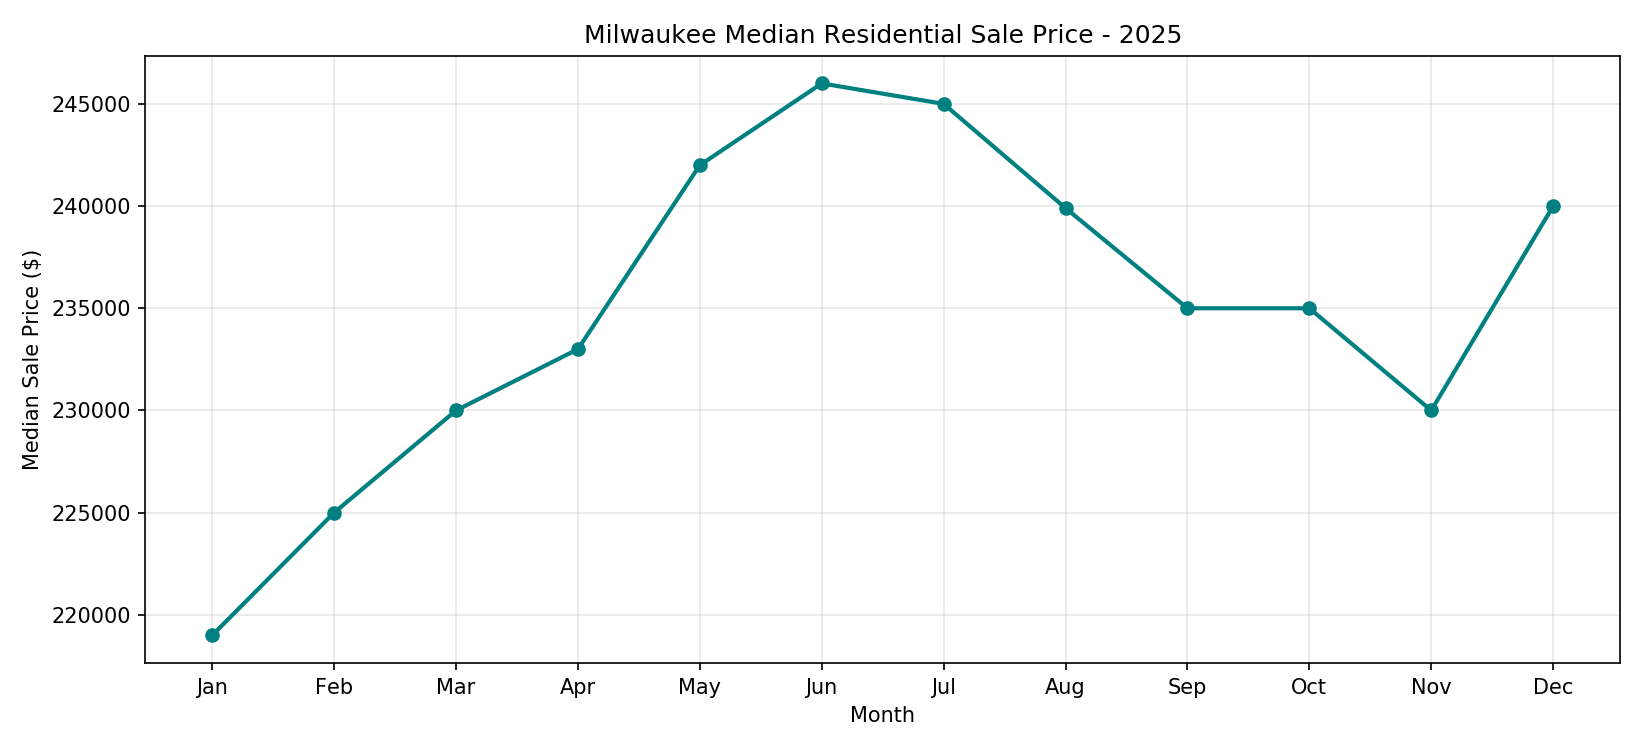

In [42]:
# Create second chart: median sale price
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    months,
    monthly_sales["Median_Price"],
    marker="o",
    linewidth=2,
    color="teal"
)

ax.set_title("Milwaukee Median Residential Sale Price - 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Median Sale Price ($)")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig("monthly_median_prices.png", dpi=150)
plt.close(fig)

display(Image(filename="monthly_median_prices.png"))

Finding 4: Monthly Residential Sales Trends
Residential sales activity increased during the spring of 2025, reaching a peak of 485 transactions in May.
February recorded the lowest transaction volume, with 257 sales.
Median sale prices increased from $219,000 in January to $246,000 in June before moderating during the second half of the year.
Business implication: The observed changes suggest that real estate professionals may benefit from considering monthly differences in transaction activity when planning marketing and sales efforts. Additional years of data would be needed to confirm recurring seasonal patterns.

## 7. Property Characteristics and Sale Prices

### Business Question
How are property size, age, and bedroom count associated
with residential sale prices?

This analysis examines relationships between property
characteristics and transaction prices.

In [43]:
# Create a dataset for property characteristics
property_features = residential.copy()

# Keep properties with valid prices and square footage
property_features = property_features[
    (property_features["Sale_price"] > 0) &
    (property_features["FinishedSqft"] > 0)
].copy()

# Check how many records remain
print("Properties available:", len(property_features))

# Calculate correlation
correlation = property_features[
    ["FinishedSqft", "Sale_price"]
].corr()

display(correlation)

('Properties available:', 4509)


,FinishedSqft,Sale_price
FinishedSqft,1.000000,0.355438
Sale_price,0.355438,1.000000


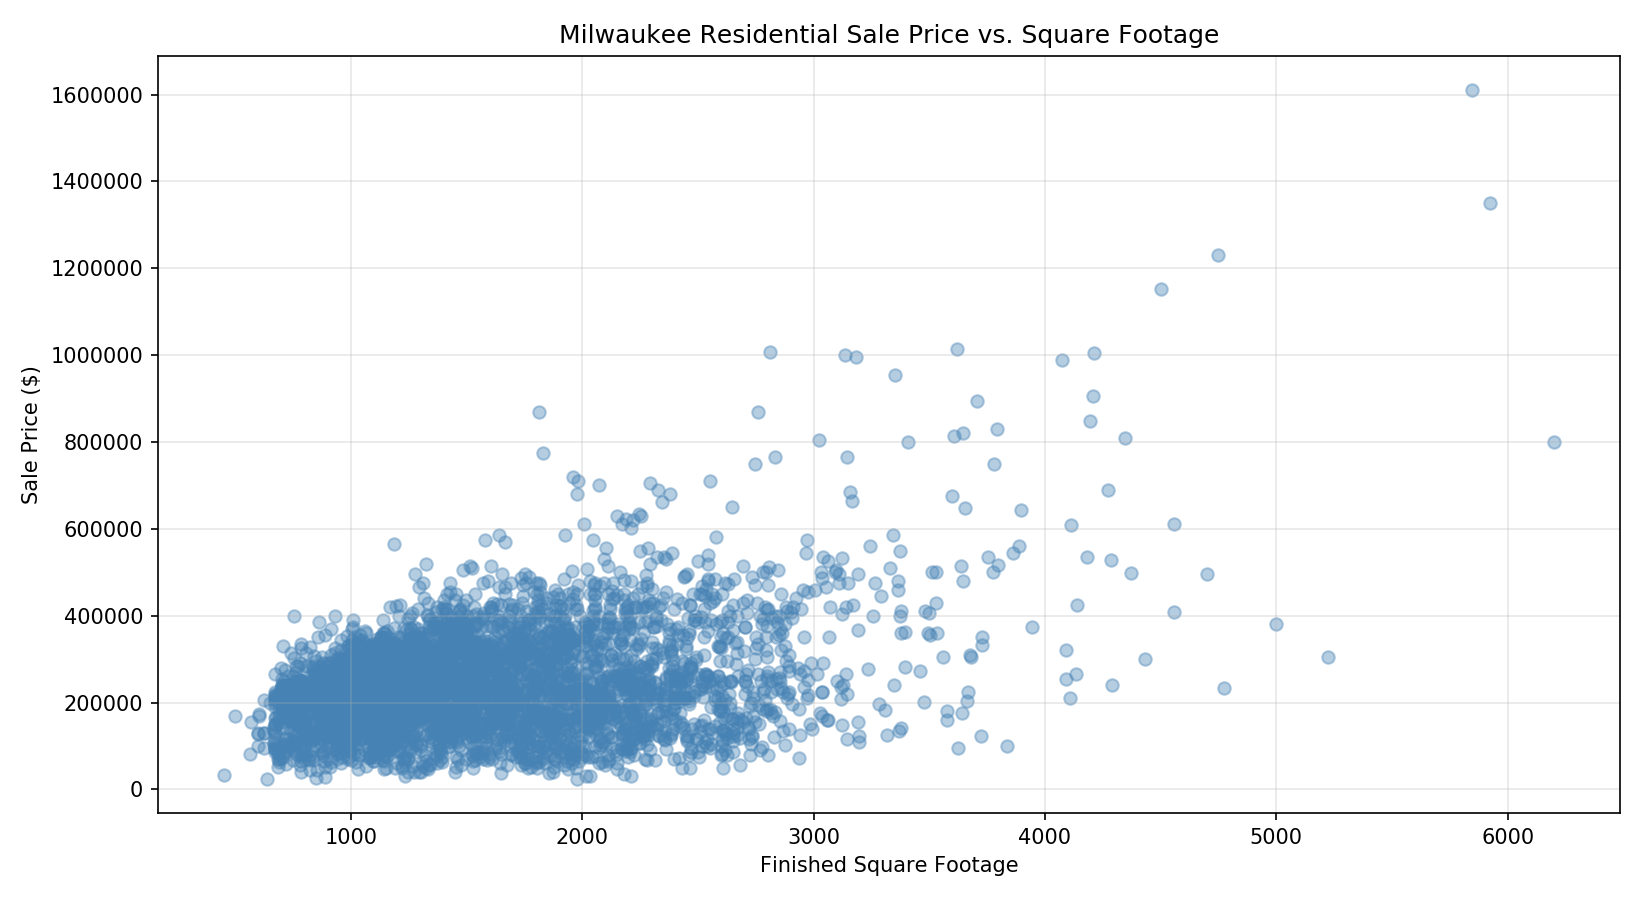

In [44]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    property_features["FinishedSqft"],
    property_features["Sale_price"],
    alpha=0.4,
    color="steelblue"
)

ax.set_title(
    "Milwaukee Residential Sale Price vs. Square Footage"
)

ax.set_xlabel("Finished Square Footage")
ax.set_ylabel("Sale Price ($)")

ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig("sqft_vs_sale_price.png", dpi=150)
plt.close(fig)

display(Image(filename="sqft_vs_sale_price.png"))

In [45]:
correlation_value = property_features[
    "FinishedSqft"
].corr(property_features["Sale_price"])

print(
    "Correlation between square footage and sale price:",
    round(correlation_value, 3)
)

('Correlation between square footage and sale price:', 0.355)


### Finding 5: Square Footage and Sale Price

The Pearson correlation coefficient between finished square
footage and residential sale price was 0.355.

This indicates a modest positive linear relationship:
larger properties generally tend to sell for higher prices,
but square footage alone does not fully explain pricing
differences.

Additional property characteristics and neighborhood
factors should be examined to better understand the
variation in sale prices.

In [46]:
# Select property characteristics
features = [
    "Sale_price",
    "FinishedSqft",
    "Bdrms",
    "Fbath",
    "Hbath",
    "Year_Built"
]

# Calculate correlations
correlations = property_features[features].corr()

# Show correlations with sale price
sale_correlations = (
    correlations["Sale_price"]
    .sort_values(ascending=False)
)

display(sale_correlations.round(3))

Sale_price      1.000
FinishedSqft    0.355
Fbath           0.289
Hbath           0.266
Year_Built      0.139
Bdrms           0.122
Name: Sale_price, dtype: float64

### Property Characteristics Correlation Analysis

This analysis examines the relationships between residential
sale prices and selected property characteristics using
Pearson correlation coefficients.

The goal is to identify which characteristics have the
strongest linear associations with sale price.

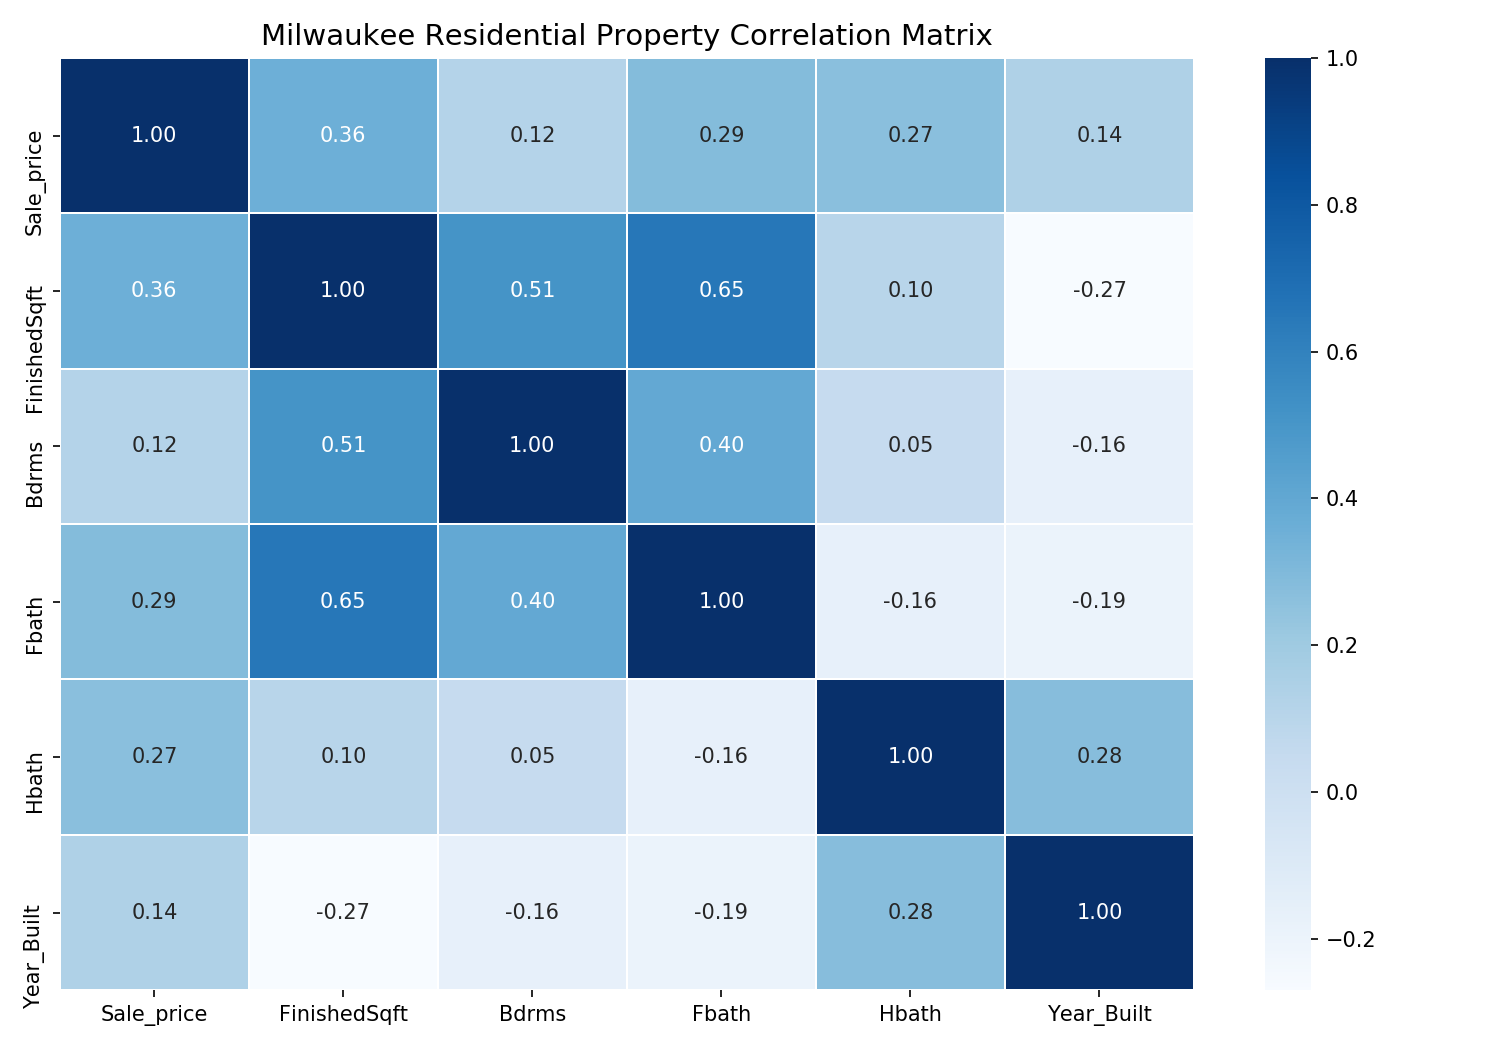

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Select variables
features = [
    "Sale_price",
    "FinishedSqft",
    "Bdrms",
    "Fbath",
    "Hbath",
    "Year_Built"
]

# Calculate correlation matrix
corr_matrix = property_features[features].corr()

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Milwaukee Residential Property Correlation Matrix",
    fontsize=14
)

plt.tight_layout()

# Save and display
fig.savefig("property_correlation_heatmap.png", dpi=150)
plt.close(fig)

display(Image(filename="property_correlation_heatmap.png"))

Finding 6: Property Characteristics and Sale Prices

Correlation analysis identified finished square footage as the strongest individual linear correlate of residential sale price (r = 0.355) among the variables examined.

Full bathrooms (r = 0.289) and half bathrooms (r = 0.266) showed stronger correlations with sale price than bedroom count (r = 0.122).

These findings suggest that property size and bathroom availability may be useful variables for further pricing analysis.

Business implication: Real estate analysts should consider multiple property characteristics alongside neighborhood location when evaluating residential sale prices. Correlation alone does not establish which characteristics independently influence pricing.

### Finding 7: Relationships Between Property Characteristics

The correlation matrix revealed that finished square footage
and full bathroom count had a relatively strong positive
correlation (r = 0.65).

Finished square footage and bedroom count were also
positively correlated (r = 0.51).

These findings indicate that several property characteristics
are related to one another.

Although square footage had the strongest individual
correlation with sale price among the variables tested,
a multivariable analysis would be needed to better
understand their independent associations with pricing.